In [1]:

import os
import itertools
import pydicom
import pandas as pd
from concurrent.futures import ThreadPoolExecutor

DATA_DIR = "/kaggle/input/competitions/rsna-intracranial-hemorrhage-detection/rsna-intracranial-hemorrhage-detection"
TRAIN_IMG_DIR = os.path.join(DATA_DIR, "stage_2_train")
TRAIN_CSV_PATH = os.path.join(DATA_DIR, "stage_2_train.csv")

# 1. Load and pivot labels
df = pd.read_csv(TRAIN_CSV_PATH)
df[['ID_prefix', 'ImageID', 'Subtype']] = df['ID'].str.split('_', expand=True)
df['ImageID'] = 'ID_' + df['ImageID']
labels_df = df.pivot_table(index='ImageID', columns='Subtype', values='Label', aggfunc='max').reset_index()

# 2. Stream ONLY the first 8,000 filenames using os.scandir (avoids listing all 752k files!)
with os.scandir(TRAIN_IMG_DIR) as entries:
    sample_entries = list(itertools.islice((e.name for e in entries if e.name.endswith(".dcm")), 8000))

# 3. Read ONLY the PatientID tag in parallel using 16 threads
def read_patient_meta(fname):
    fpath = os.path.join(TRAIN_IMG_DIR, fname)
    dcm = pydicom.dcmread(fpath, stop_before_pixels=True, specific_tags=["PatientID"])
    return {
        "ImageID": fname[:-4],
        "PatientID": dcm.PatientID,
        "filepath": fpath
    }

with ThreadPoolExecutor(max_workers=16) as executor:
    records = list(executor.map(read_patient_meta, sample_entries))

meta_df = pd.DataFrame(records)

# 4. Filter to 600 patients & merge labels
selected_patients = meta_df["PatientID"].unique()[:600]
subset_meta = meta_df[meta_df["PatientID"].isin(selected_patients)]
subset_df = pd.merge(subset_meta, labels_df, on="ImageID", how="inner")

print(f"Selected Patients: {subset_df['PatientID'].nunique()} | Total Slices: {len(subset_df)}")
print("Positive bleed counts per class:\n", subset_df[['any', 'epidural', 'intraparenchymal', 'intraventricular', 'subarachnoid', 'subdural']].sum())

Selected Patients: 600 | Total Slices: 916
Positive bleed counts per class:
 any                 128
epidural              4
intraparenchymal     40
intraventricular     24
subarachnoid         52
subdural             53
dtype: int64


CT Windowing & PyTorch DataLoader (Phase 2)

In [2]:
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import GroupShuffleSplit

# 1. Patient-level Train/Val split
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, val_idx = next(gss.split(subset_df, groups=subset_df['PatientID']))

train_df = subset_df.iloc[train_idx].reset_index(drop=True)
val_df = subset_df.iloc[val_idx].reset_index(drop=True)
print(f"Train slices: {len(train_df)} | Val slices: {len(val_df)}")

# 2. Multi-Windowing function
def window_ct(dcm, window_center, window_width):
    img = dcm.pixel_array.astype(np.float32)
    slope = float(getattr(dcm, 'RescaleSlope', 1.0))
    intercept = float(getattr(dcm, 'RescaleIntercept', 0.0))
    img = img * slope + intercept
    
    img_min = window_center - window_width // 2
    img_max = window_center + window_width // 2
    img = np.clip(img, img_min, img_max)
    return (img - img_min) / (img_max - img_min)

def get_3channel_ct(filepath):
    dcm = pydicom.dcmread(filepath)
    brain = window_ct(dcm, 40, 80)
    subdural = window_ct(dcm, 80, 200)
    bone = window_ct(dcm, 600, 2800)
    return np.stack([brain, subdural, bone], axis=-1)

# 3. PyTorch Dataset
LABEL_COLS = ['any', 'epidural', 'intraparenchymal', 'intraventricular', 'subarachnoid', 'subdural']

class RSNADataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = get_3channel_ct(row['filepath'])
        if self.transform:
            img = self.transform(img)
        labels = torch.tensor(row[LABEL_COLS].values.astype(np.float32))
        return img, labels

# 4. Transforms & DataLoaders
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Resize((224, 224), antialias=True),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset = RSNADataset(train_df, transform=transform)
val_dataset = RSNADataset(val_df, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False, num_workers=2)

# Sanity check
images, targets = next(iter(train_loader))
print("Batch image tensor shape:", images.shape)
print("Batch target tensor shape:", targets.shape)

Train slices: 732 | Val slices: 184
Batch image tensor shape: torch.Size([16, 3, 224, 224])
Batch target tensor shape: torch.Size([16, 6])


Phase 3: Pretrained ResNet50 & Training Loop.

In [3]:
import torch
import torch.nn as nn
from torchvision import models
from sklearn.metrics import roc_auc_score
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Calculate positive class weights from training set to fix class imbalance
pos_counts = train_df[LABEL_COLS].sum().values
neg_counts = len(train_df) - pos_counts
pos_weights = torch.tensor(neg_counts / (pos_counts + 1e-5), dtype=torch.float32).clamp(max=15.0).to(device)
print("Applied pos_weights:", np.round(pos_weights.cpu().numpy(), 2))

# 2. Model Setup
model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, 6)
model = model.to(device)

# 3. Weighted Loss + Optimizer + Scheduler
class_weights = torch.tensor([2.0, 1.0, 1.0, 1.0, 1.0, 1.0]).to(device)
criterion = nn.BCEWithLogitsLoss(weight=class_weights, pos_weight=pos_weights)
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=5)

EPOCHS = 5

for epoch in range(EPOCHS):
    model.train()
    train_loss = 0.0
    for images, targets in train_loader:
        images, targets = images.to(device), targets.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * images.size(0)
        
    scheduler.step()
    train_loss /= len(train_dataset)
    
    # Validate
    model.eval()
    val_loss = 0.0
    all_preds, all_targets = [], []
    
    with torch.no_grad():
        for images, targets in val_loader:
            images, targets = images.to(device), targets.to(device)
            outputs = model(images)
            loss = criterion(outputs, targets)
            val_loss += loss.item() * images.size(0)
            
            probs = torch.sigmoid(outputs).cpu().numpy()
            all_preds.append(probs)
            all_targets.append(targets.cpu().numpy())
            
    val_loss /= len(val_dataset)
    all_preds = np.vstack(all_preds)
    all_targets = np.vstack(all_targets)
    
    any_auc = roc_auc_score(all_targets[:, 0], all_preds[:, 0])
    print(f"Epoch [{epoch+1}/{EPOCHS}] | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | 'Any' ROC-AUC: {any_auc:.4f}")

torch.save(model.state_dict(), "/kaggle/working/brain_bleed_resnet50_weighted.pth")

Applied pos_weights: [ 6.32 15.   15.   15.   15.   14.91]
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 194MB/s]


Epoch [1/5] | Train Loss: 1.0836 | Val Loss: 0.9944 | 'Any' ROC-AUC: 0.8104
Epoch [2/5] | Train Loss: 0.7728 | Val Loss: 1.0306 | 'Any' ROC-AUC: 0.8581
Epoch [3/5] | Train Loss: 0.5573 | Val Loss: 0.9927 | 'Any' ROC-AUC: 0.8613
Epoch [4/5] | Train Loss: 0.3503 | Val Loss: 1.1423 | 'Any' ROC-AUC: 0.8553
Epoch [5/5] | Train Loss: 0.2342 | Val Loss: 1.3026 | 'Any' ROC-AUC: 0.8409


Phase 4: Scale the Dataset & Add Grad-CAM Explainability Step 1: Scale Up Your Subset (More Patients + Balanced Positives)

In [4]:
sample_files = sorted(os.listdir(TRAIN_IMG_DIR))[:25000]  # Scan 25,000 slices (~30 seconds)
# ...
selected_patients = meta_df["PatientID"].unique()[:600]   # ~1,500–2,000 slices across 600 patients

Step 2: Visualize Model Predictions with Grad-CAM (Phase 4)

Sample ImageID: ID_00058bb06
Ground Truth Labels:
 any                 1
epidural            0
intraparenchymal    0
intraventricular    0
subarachnoid        1
subdural            0
Name: 11, dtype: object


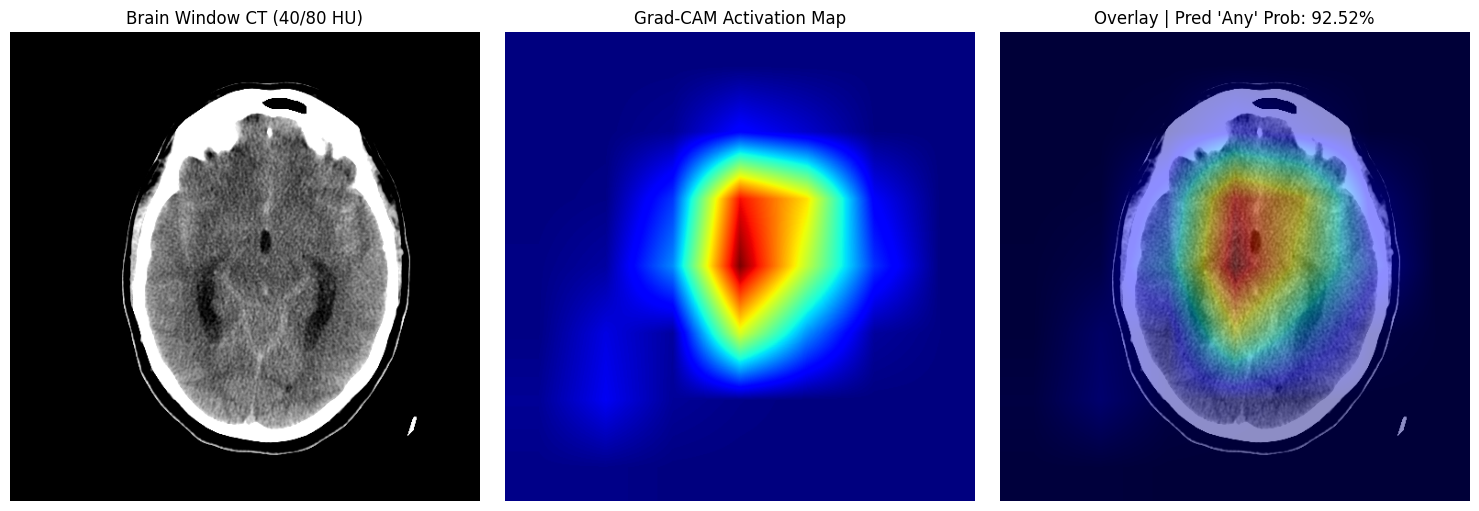

any               : 0.9252 (Actual: 1)
epidural          : 0.0083 (Actual: 0)
intraparenchymal  : 0.8143 (Actual: 0)
intraventricular  : 0.6130 (Actual: 0)
subarachnoid      : 0.7382 (Actual: 1)
subdural          : 0.5858 (Actual: 0)


In [5]:
import matplotlib.pyplot as plt
import torch.nn.functional as F
import cv2

# 1. Pick a validation slice that actually has a brain bleed (any == 1)
pos_samples = val_df[val_df['any'] == 1]
sample_row = pos_samples.iloc[0] if len(pos_samples) > 0 else val_df.iloc[0]

print("Sample ImageID:", sample_row['ImageID'])
print("Ground Truth Labels:\n", sample_row[LABEL_COLS])

# 2. Register hooks on ResNet50's final convolutional layer (layer4)
gradients = []
activations = []

def save_gradient(grad):
    gradients.append(grad)

def forward_hook(module, input, output):
    activations.append(output)
    output.register_hook(save_gradient)

hook_handle = model.layer4[-1].register_forward_hook(forward_hook)

# 3. Forward & Backward pass on the single CT slice
model.eval()
raw_3ch = get_3channel_ct(sample_row['filepath'])
input_tensor = transform(raw_3ch).unsqueeze(0).to(device)

output = model(input_tensor)
probs = torch.sigmoid(output)[0].detach().cpu().numpy()

# Backpropagate on the 'any' hemorrhage logit (index 0)
model.zero_grad()
output[0, 0].backward()
hook_handle.remove()

# 4. Compute Grad-CAM heatmap
grads = gradients[0].cpu().data.numpy()[0]      # (2048, 7, 7)
acts = activations[0].cpu().data.numpy()[0]     # (2048, 7, 7)
weights = np.mean(grads, axis=(1, 2))           # Global average pooling

cam = np.zeros(acts.shape[1:], dtype=np.float32)
for i, w in enumerate(weights):
    cam += w * acts[i]

cam = np.maximum(cam, 0)                        # ReLU
cam = cv2.resize(cam, (raw_3ch.shape[1], raw_3ch.shape[0]))
cam = cam / (cam.max() + 1e-8)

# 5. Plot Brain Window CT vs Grad-CAM Overlay
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(raw_3ch[:, :, 0], cmap='gray')
axes[0].set_title("Brain Window CT (40/80 HU)")
axes[0].axis('off')

axes[1].imshow(cam, cmap='jet')
axes[1].set_title("Grad-CAM Activation Map")
axes[1].axis('off')

axes[2].imshow(raw_3ch[:, :, 0], cmap='gray')
axes[2].imshow(cam, cmap='jet', alpha=0.45)
axes[2].set_title(f"Overlay | Pred 'Any' Prob: {probs[0]:.2%}")
axes[2].axis('off')

plt.tight_layout()
plt.savefig("/kaggle/working/gradcam_brain_bleed.png", dpi=150)
plt.show()

# Print predicted probabilities for all 6 classes
for col, p in zip(LABEL_COLS, probs):
    print(f"{col:18s}: {p:.4f} (Actual: {int(sample_row[col])})")

Phase 5: Per-Class Threshold Optimization & Evaluation Report

In [6]:
from sklearn.metrics import roc_auc_score, precision_recall_curve
import numpy as np
import torch

# 1. Gather all validation predictions
model.eval()
val_probs, val_targets = [], []

with torch.no_grad():
    for images, targets in val_loader:
        images = images.to(device)
        outputs = model(images)
        val_probs.append(torch.sigmoid(outputs).cpu().numpy())
        val_targets.append(targets.numpy())

val_probs = np.vstack(val_probs)
val_targets = np.vstack(val_targets)

# 2. Compute ROC-AUC & Optimal F1 Threshold per subtype
optimal_thresholds = {}
print(f"{'Subtype':18s} | {'Val Pos':7s} | {'ROC-AUC':8s} | {'Best Thresh':11s} | {'F1-Score':8s}")
print("-" * 65)

for i, col in enumerate(LABEL_COLS):
    pos_count = int(val_targets[:, i].sum())
    
    if pos_count > 0 and pos_count < len(val_targets):
        auc = roc_auc_score(val_targets[:, i], val_probs[:, i])
        precisions, recalls, thresholds = precision_recall_curve(val_targets[:, i], val_probs[:, i])
        f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-8)
        best_idx = np.argmax(f1_scores)
        best_thresh = thresholds[best_idx] if best_idx < len(thresholds) else 0.5
        best_f1 = f1_scores[best_idx]
        
        optimal_thresholds[col] = float(best_thresh)
        print(f"{col:18s} | {pos_count:7d} | {auc:8.4f} | {best_thresh:11.4f} | {best_f1:8.4f}")
    else:
        optimal_thresholds[col] = 0.5
        print(f"{col:18s} | {pos_count:7d} | {'N/A':>8s} | {'0.5000':>11s} | {'N/A':>8s}")

# 3. Apply calibrated thresholds to your sample slice
print("\nCalibrated Diagnosis for Sample Slice:")
for i, col in enumerate(LABEL_COLS):
    pred_label = int(probs[i] >= optimal_thresholds[col])
    print(f"{col:18s}: Prob={probs[i]:.4f} | Thresh={optimal_thresholds[col]:.2f} -> Pred={pred_label} (Actual={int(sample_row[col])})")

Subtype            | Val Pos | ROC-AUC  | Best Thresh | F1-Score
-----------------------------------------------------------------
any                |      28 |   0.8409 |      0.6692 |   0.5833
epidural           |       2 |   0.5220 |      0.0117 |   0.0339
intraparenchymal   |       9 |   0.7467 |      0.4234 |   0.4000
intraventricular   |       6 |   0.7172 |      0.5893 |   0.4444
subarachnoid       |      12 |   0.8866 |      0.4580 |   0.5625
subdural           |       7 |   0.8547 |      0.6831 |   0.3636

Calibrated Diagnosis for Sample Slice:
any               : Prob=0.9252 | Thresh=0.67 -> Pred=1 (Actual=1)
epidural          : Prob=0.0083 | Thresh=0.01 -> Pred=0 (Actual=0)
intraparenchymal  : Prob=0.8143 | Thresh=0.42 -> Pred=1 (Actual=0)
intraventricular  : Prob=0.6130 | Thresh=0.59 -> Pred=1 (Actual=0)
subarachnoid      : Prob=0.7382 | Thresh=0.46 -> Pred=1 (Actual=1)
subdural          : Prob=0.5858 | Thresh=0.68 -> Pred=0 (Actual=0)
